# Plán letu nad Brněnskou přehradou: GSD, překryvy, terén a vítr

[![Otevřít v Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/flight_planner_brno_cs.ipynb)

**OpenSkyLab · notebook k vizuálu** [Plánovač letu dronu](https://openskylab.space/edu_viz_flight_planner.html) · [English version](flight_planner_brno_en.ipynb)

Ve vizuálu jsi plánoval let nad rovinou a nad modelovým kopcem. Tady stejné vzorce použiješ na skutečný terén: svah nad Brněnskou přehradou u Kozí horky v Brně-Bystrci z digitálního modelu reliéfu ČÚZK DMR 5G (lidar, buňka 2 m) a na aktuální předpověď větru ve výšce letu.

**Cíl:** spočítat výšku letu pro cílové GSD, rozestup linek, interval a rychlost, rozmazání a zkosení, ukázat, jak terén mění výšku nad zemí a překryv, a naplánovat návrat proti větru.

**Data:** DMR 5G (ČÚZK, služba ImageServer, výšky v Bpv, buňka 2 m) pro území 1,2 × 0,8 km na svahu nad Brněnskou přehradou u Kozí horky (Brno-Bystrc); hodinová předpověď větru ve 10, 80 a 120 m z Open-Meteo; parametry kamer z technických listů výrobců (stejné jako ve vizuálu).

**Úkoly:** pět. Odpovědi piš do buněk *Tvoje odpověď* pod úkoly. Řádky označené `# ◀ parametr` můžeš měnit a buňku spustit znovu (Shift + Enter).

**Čas:** asi 50 min. Potřebuješ Google účet (Colab); nic se neinstaluje do počítače. Buňky spouštěj popořadě shora dolů.

## 1. Příprava

In [1]:
%pip install -q rasterio

Note: you may need to restart the kernel to use updated packages.


In [2]:
import time, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import rasterio
from pyproj import Transformer

def cuzk_raster(service, x0, y0, x1, y1, res=2.0):
    """Výřez rastru ČÚZK (dmr5g, dmp1g, dmp_obrazova_korelace) v S-JTSK (EPSG:5514), výšky v Bpv.
    Vrací pole výšek (řádek 0 = sever) a jeho transformaci."""
    nx, ny = int(round((x1 - x0) / res)), int(round((y1 - y0) / res))
    url = f"https://ags.cuzk.cz/arcgis2/rest/services/{service}/ImageServer/exportImage"
    params = {"bbox": f"{x0},{y0},{x1},{y1}", "bboxSR": 5514, "imageSR": 5514, "size": f"{nx},{ny}",
              "format": "tiff", "pixelType": "F32", "interpolation": "RSP_BilinearInterpolation", "f": "image"}
    for attempt in range(4):
        r = requests.get(url, params=params, timeout=120)
        if r.ok and r.headers.get("content-type", "").startswith("image"):
            break
        time.sleep(3 * (attempt + 1))
    r.raise_for_status()
    with rasterio.MemoryFile(r.content) as mem, mem.open() as ds:
        return ds.read(1).astype(float), ds.transform

def open_meteo(params, tries=6):
    """Dotaz na Open-Meteo; při chybě nebo vyčerpaném limitu to zkusí znovu."""
    for i in range(tries):
        try:
            r = requests.get("https://api.open-meteo.com/v1/forecast", params=params, timeout=60)
            if r.ok:
                return r.json()
            reason = r.json().get("reason", r.status_code)
        except requests.RequestException as e:
            reason = type(e).__name__
        print("Open-Meteo:", reason, "– zkusím znovu"); time.sleep(5 * (i + 1))
    raise RuntimeError("Open-Meteo neodpovídá, spusť buňku za chvíli znovu.")

# kamery: šířka a výška čipu (mm), počet pixelů, ohnisková vzdálenost (mm), nejkratší interval mezi snímky (s)
CAMERAS = {
    "P1 35 mm":        dict(sw=35.9, sh=24.0, pw=8192, ph=5460, f=35.0, tmin=0.7),
    "Mavic 3E":        dict(sw=17.3, sh=13.0, pw=5280, ph=3956, f=12.3, tmin=0.7),
    "Mavic 3M (MS)":   dict(sw=5.2,  sh=3.9,  pw=2592, ph=1944, f=4.34, tmin=2.0),
    "RGB 1″ 20 Mpx":   dict(sw=13.2, sh=8.8,  pw=5472, ph=3648, f=8.8,  tmin=2.0),
}

## 2. Kamera, výška a GSD

GSD = H · p / f, kde p je velikost pixelu na čipu (šířka čipu / počet pixelů). Z cílového GSD tedy H = GSD · f / p.

In [3]:
gsd_target = 1.5          # ◀ parametr: cílové GSD v cm/px
rows = []
for name, c in CAMERAS.items():
    p = c["sw"] / c["pw"]                       # mm
    H = gsd_target / 100 * c["f"] / p          # m
    rows.append({"kamera": name, "pixel na čipu (µm)": p * 1000, "výška letu (m)": H,
                 "záběr napříč (m)": c["pw"] * gsd_target / 100, "záběr podél (m)": c["ph"] * gsd_target / 100})
cam_tab = pd.DataFrame(rows).set_index("kamera")
cam_tab.round(1)

,pixel na čipu (µm),výška letu (m),záběr napříč (m),záběr podél (m)
kamera,,,,
P1 35 mm,4.4,119.8,122.9,81.9
Mavic 3E,3.3,56.3,79.2,59.3
Mavic 3M (MS),2.0,32.4,38.9,29.2
RGB 1″ 20 Mpx,2.4,54.7,82.1,54.7


> **✏️ Úkol 1.** Proč musí Mavic 3M pro stejné GSD letět mnohem níž než P1? Nastav `gsd_target` na 2 a pak na 4 cm/px. Pro které kamery a GSD by výška překročila 120 m, a tedy limit otevřené kategorie? Jaké má nízký let důsledky (počet snímků, čas, bezpečnost)?

*Tvoje odpověď:* 

## 3. Skutečný terén a plán linek

Načteme DMR 5G pro svah nad Brněnskou přehradou. Linky vedou ve směru východ–západ, tedy po spádnici dolů a zpět nahoru. Místo vzletu je na loukách na horním, západním okraji.

terén 227.2–416.5 m n. m. (Bpv), místo vzletu 401.4 m n. m.


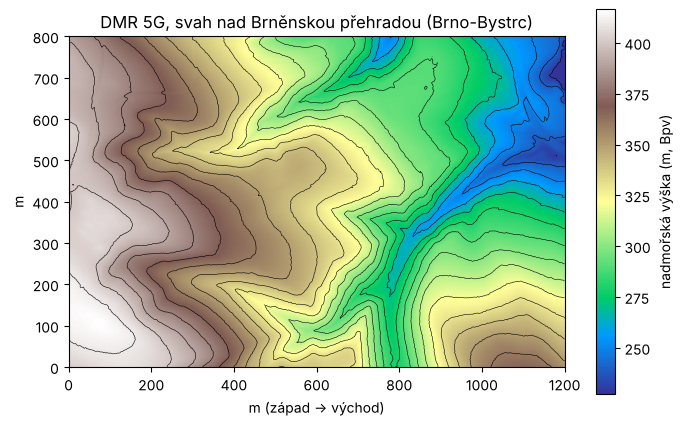

In [4]:
cx, cy = Transformer.from_crs(4326, 5514, always_xy=True).transform(16.4798, 49.2467)
W, Hh = 1200, 800                                  # území: šířka (V–Z) a výška (S–J) v m
dem, tr = cuzk_raster("dmr5g", cx - W / 2, cy - Hh / 2, cx + W / 2, cy + Hh / 2, res=2)
z_takeoff = float(np.median(dem[:, :10]))            # horní, západní okraj území
print(f"terén {dem.min():.1f}–{dem.max():.1f} m n. m. (Bpv), místo vzletu {z_takeoff:.1f} m n. m.")
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(dem, cmap="terrain", extent=(0, W, 0, Hh)); fig.colorbar(im, label="nadmořská výška (m, Bpv)")
ax.contour(np.flipud(dem), levels=np.arange(np.floor(dem.min() / 10) * 10, dem.max() + 10, 10), colors="k", linewidths=0.4, extent=(0, W, 0, Hh))
ax.set(xlabel="m (západ → východ)", ylabel="m", title="DMR 5G, svah nad Brněnskou přehradou (Brno-Bystrc)"); plt.show()

In [5]:
cam = CAMERAS["Mavic 3E"]     # ◀ parametr: kamera
H0 = 80                       # ◀ parametr: výška letu nad místem vzletu (m)
fo, so = 0.80, 0.70           # ◀ parametr: podélný a příčný překryv
v_air = 10.0                  # ◀ parametr: rychlost vůči vzduchu (m/s)
long_across = True            # ◀ parametr: delší strana snímku napříč letem?

p = cam["sw"] / cam["pw"] / 1000                                   # m
n_across, n_along = (cam["pw"], cam["ph"]) if long_across else (cam["ph"], cam["pw"])
gsd0 = H0 * p / (cam["f"] / 1000)                                  # GSD nad místem vzletu
base = (1 - fo) * n_along * gsd0                                   # vzdálenost mezi snímky
spacing = (1 - so) * n_across * gsd0                               # rozestup linek
n_lines = int(np.ceil(Hh / spacing)) + 1
interval = base / v_air
photos = n_lines * (int(W / base) + 1)
t_flight = (n_lines * W + (n_lines - 1) * spacing) / v_air
print(f"GSD nad místem vzletu {gsd0 * 100:.2f} cm/px, báze {base:.1f} m, rozestup linek {spacing:.1f} m")
print(f"linek {n_lines}, snímků {photos}, interval {interval:.2f} s (kamera zvládne {cam['tmin']} s), čas letu {t_flight / 60:.1f} min bez otoček")
if interval < cam["tmin"]:
    print(f"POZOR: kamera nestihne; nejvyšší rychlost je {base / cam['tmin']:.1f} m/s")

GSD nad místem vzletu 2.13 cm/px, báze 16.9 m, rozestup linek 33.8 m
linek 25, snímků 1800, interval 1.69 s (kamera zvládne 0.7 s), čas letu 51.4 min bez otoček


> **✏️ Úkol 2.** Zvyšuj `v_air`, dokud se neobjeví upozornění, že kamera nestihne. Jaká je nejvyšší rychlost? Přepni `long_across = False`: jak se změní báze, nejvyšší rychlost, počet linek a čas letu? Proč otočený snímek dovolí rychlejší let, a přesto může let trvat déle? Nastav podélný překryv 0,85 jako pro vegetaci.

*Tvoje odpověď:* 

## 4. Stálá výška, nebo sledování terénu?

Při stálé výšce nad místem vzletu se výška nad zemí mění s terénem: H_AGL = H0 + z_vzlet − z. S ní se mění GSD i záběr, ale báze a rozestup linek zůstávají, takže se mění skutečný překryv.

výška nad zemí 65–254 m, GSD 1.73–6.77 cm/px
podélný překryv 75%–94%, příčný 63%–91%
plocha nad 120 m nad terénem: 74% území


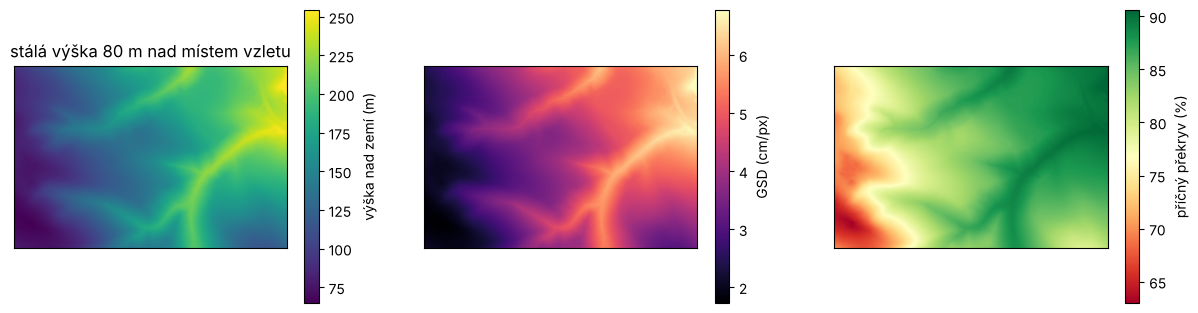

In [6]:
follow = False                # ◀ parametr: True = sledování terénu (stálá výška nad zemí H0)
agl = np.full_like(dem, H0) if follow else H0 + z_takeoff - dem
gsd = agl * p / (cam["f"] / 1000)
fo_local = 1 - base / (n_along * gsd)
so_local = 1 - spacing / (n_across * gsd)
print(f"výška nad zemí {agl.min():.0f}–{agl.max():.0f} m, GSD {gsd.min() * 100:.2f}–{gsd.max() * 100:.2f} cm/px")
print(f"podélný překryv {fo_local.min():.0%}–{fo_local.max():.0%}, příčný {so_local.min():.0%}–{so_local.max():.0%}")
print(f"plocha nad 120 m nad terénem: {np.mean(agl > 120):.0%} území")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, (arr, lbl, cm) in zip(ax, [(agl, "výška nad zemí (m)", "viridis"), (gsd * 100, "GSD (cm/px)", "magma"), (so_local * 100, "příčný překryv (%)", "RdYlGn")]):
    im = a.imshow(arr, cmap=cm, extent=(0, W, 0, Hh)); fig.colorbar(im, ax=a, label=lbl); a.set_xticks([]); a.set_yticks([])
ax[0].set_title("sledování terénu" if follow else f"stálá výška {H0} m nad místem vzletu"); plt.show()

> **✏️ Úkol 3.** Při stálé výšce 80 m nad místem vzletu: jaký je rozsah GSD a překryvů? Kde je překryv nejmenší, nahoře u místa vzletu, nebo v nejnižších místech, a proč? Kolik území je výš než 120 m nad terénem? Přepni `follow = True`: co se zlepší a co k sledování terénu potřebuješ (model terénu, jeho přesnost, překážky)?

*Tvoje odpověď:* 

## 5. Skutečný vítr, rozmazání a postupná závěrka

Z Open-Meteo vezmeme předpověď větru pro toto území na dnešek. Rozmazání = rychlost vůči zemi · expozice / GSD; zkosení postupnou závěrkou = rychlost vůči zemi · doba vyčtení čipu / GSD. Zenmuse P1 a Mavic 3E mají mechanickou závěrku, takže u nich zkosení prakticky odpadá (t_read = 0); výchozích 30 ms je řádová hodnota pro elektronickou postupnou závěrku.

In [7]:
w = open_meteo({"latitude": 49.2467, "longitude": 16.4798, "forecast_days": 1, "wind_speed_unit": "ms", "timezone": "Europe/Prague",
                "hourly": "wind_speed_10m,wind_speed_80m,wind_speed_120m,wind_direction_80m,wind_gusts_10m"})
met = pd.DataFrame(w["hourly"]).set_index("time")
print(met.iloc[6:20].to_string())

                  wind_speed_10m  wind_speed_80m  wind_speed_120m  wind_direction_80m  wind_gusts_10m
time                                                                                                 
2026-10-31T06:00            2.95            5.52             6.61                 338             5.4
2026-10-31T07:00            3.55            6.44             7.38                 327             6.5
2026-10-31T08:00            3.66            6.14             6.80                 330             7.3
2026-10-31T09:00            3.78            5.99             6.47                 327             7.1
2026-10-31T10:00            3.86            5.77             6.07                 326             7.5
2026-10-31T11:00            4.58            6.59             6.90                 330             8.9
2026-10-31T12:00            4.52            6.58             6.89                 336             8.9
2026-10-31T13:00            4.16            6.17             6.40                 

In [8]:
hour = 6 + int(met.wind_speed_80m.values[6:21].argmax())   # ◀ parametr: hodina letu (místní čas); výchozí je největrnější hodina mezi 6 a 20 h
t_exp = 1 / 1000               # ◀ parametr: expoziční čas (s)
t_read = 0.030                 # ◀ parametr: doba vyčtení čipu u postupné závěrky (s); 0 = globální závěrka
wind = met.wind_speed_80m.iloc[hour]
wdir = met.wind_direction_80m.iloc[hour]
# linky vedou V–Z; složka větru podél linek a napříč nimi
along = wind * np.cos(np.radians(wdir - 90)); cross = wind * np.sin(np.radians(wdir - 90))
for leg, sign in [("linka na východ", -1), ("linka na západ", +1)]:
    gs = np.sqrt(max(v_air**2 - cross**2, 0)) + sign * along      # rychlost vůči zemi (vítr odkud → znaménko)
    print(f"{leg}: vůči zemi {gs:4.1f} m/s, rozmazání {gs * t_exp / gsd0:.2f} px, zkosení {gs * t_read / gsd0:.1f} px")
print(f"{met.index[hour]}: vítr v 80 m: {wind:.1f} m/s od {wdir:.0f}°; složka k východu {-along:+.1f} m/s, k severu {cross:+.1f} m/s")

linka na východ: vůči zemi  9.9 m/s, rozmazání 0.46 px, zkosení 13.9 px
linka na západ: vůči zemi  4.0 m/s, rozmazání 0.19 px, zkosení 5.7 px
2026-10-31T15:00: vítr v 80 m: 7.8 m/s od 338°; složka k východu +2.9 m/s, k severu -7.2 m/s


> **✏️ Úkol 4.** Jaký vítr hlásí předpověď ve 10, 80 a 120 m a proč se liší? Jak se liší rozmazání a zkosení na lince po větru a proti větru? Proč zkosení nezmenší kratší expozice? Kdy bys linky raději otočil podél větru, nebo napříč?

*Tvoje odpověď:* 

## 6. Baterie a návrat domů

Mavic 3E má baterii 77 Wh a výrobce udává až 45 min letu bez větru, tedy průměrně asi 100 W. Spočítáme, kolik energie potřebuje návrat z nejvzdálenějšího bodu, když vítr fouká od místa vzletu.

In [9]:
E_bat = 77.0                  # ◀ parametr: energie baterie (Wh)
P = 77.0 / (45 / 60)          # průměrný výkon (W) z udávané výdrže
temp_factor = 1.0             # ◀ parametr: využitelná kapacita (1,0 při 20 °C; v mrazu zhruba 0,7–0,8)
reserve = 0.20                # ◀ parametr: rezerva při přistání
headwind = wind               # nejhorší případ: celý vítr proti návratu
d_home = np.hypot(W, Hh)      # nejvzdálenější roh území (m)
gs_home = v_air - headwind
E_mission = P * t_flight / 3600
E_return = P * d_home / max(gs_home, 0.1) / 3600
E_use = E_bat * temp_factor * (1 - reserve)
print(f"mise {E_mission:.1f} Wh + návrat {E_return:.1f} Wh (proti větru {headwind:.1f} m/s, vůči zemi {gs_home:.1f} m/s) = {E_mission + E_return:.1f} Wh")
print(f"využitelná energie {E_use:.1f} Wh → {'stačí' if E_mission + E_return <= E_use else 'NESTAČÍ, rozděl misi'}")

mise 87.9 Wh + návrat 18.4 Wh (proti větru 7.8 m/s, vůči zemi 2.2 m/s) = 106.2 Wh
využitelná energie 61.6 Wh → NESTAČÍ, rozděl misi


> **✏️ Úkol 5.** Stačí jedna baterie? Nastav `temp_factor = 0.75` a pak zvyš vítr (`headwind = 8`). Proč je „tam po větru, zpátky proti větru“ past? Zkus také vyšší `v_air`: proč při silném větru pomáhá letět rychleji, i když výkon roste?

*Tvoje odpověď:* 

> **✏️ Rozšíření (nepovinné).** Spolužáci mohou mít notebook pro jiné území (Roztoky, Brno-Bystrc, Hosín u Hluboké). Porovnejte převýšení, rozsah výšky nad zemí při stálé výšce 80 m nad místem vzletu a podíl území nad 120 m. Kde by stálá výška byla nejméně vhodná a kolik baterií by na území potřeboval každý z vás?

*Tvoje odpověď:* 

---
### Zdroje dat a literatura

- Digitální model reliéfu České republiky 5. generace (DMR 5G), © ČÚZK, licence CC BY 4.0, služba https://ags.cuzk.cz/arcgis2/rest/services/dmr5g/ImageServer
- Počasí: Open-Meteo.com (CC BY 4.0), https://open-meteo.com
- Parametry kamer: technické listy DJI Zenmuse P1, Mavic 3 Enterprise (3E, 3M) a obecná kamera 1″ 20 Mpx (u Mavic 3M a obecné kamery je nejkratší interval 2 s orientační hodnota); baterie Mavic 3 Enterprise 5000 mAh, 15,4 V (77 Wh).
- Výška letu v otevřené kategorii max. 120 m od nejbližšího bodu zemského povrchu: prováděcí nařízení Komise (EU) 2019/947, příloha, UAS.OPEN.010.

### Jak citovat

OpenSkyLab (2026). Plán letu nad Brněnskou přehradou: GSD, překryvy, terén a vítr [notebook, výukový materiál], verze 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/flight_planner_brno_cs.ipynb. Licence CC BY 4.0.

Text a kód notebooku: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data mají licence svých poskytovatelů (viz výše).

*Materiál připravil tým OpenSkyLab s pomocí generativní AI Claude (Anthropic), která pomáhala s návrhem kódu a textu. Za obsah odpovídají autoři.*